<a href="https://colab.research.google.com/github/fdegolla/MAT-422-Francisco-Degollado/blob/main/MAT422_HW_3_5_3_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix


# MAT 422 - Homework 3.5 and 3.6

**Name:** Francisco Degollado

## Topics
- 3.5 K-means Clustering
- 3.6 Support Vector Machines

## 3.5 K-means Clustering

K-means clustering is an unsupervised machine learning method used to divide data into groups based on similarities between observations.

The algorithm assigns each data point to the nearest cluster center, called a centroid. The centroids are then updated using the mean of the points assigned to each cluster. This process repeats until the clusters stabilize.

The objective of K-means is to minimize the sum of squared distances between each data point and its assigned centroid.

**K-means Objective Function:**

$$
J = \sum_{i=1}^{k}\sum_{x \in C_i}\|x-\mu_i\|^2
$$

where:

- **k** is the number of clusters.
- **Cᵢ** represents cluster i.
- **x** represents a data point.
- **μᵢ** represents the centroid of cluster i.
- **J** represents the total within-cluster sum of squared distances.

In this example, we will use Python to group two-dimensional data points into three clusters and visualize the results.

In [2]:

# Create a two-dimensional dataset
X = np.array([
    [1, 2], [2, 1], [2, 3], [3, 2], [1, 3],
    [6, 7], [7, 6], [7, 8], [8, 7], [6, 8],
    [11, 2], [12, 1], [12, 3], [13, 2], [11, 3]
])

# Apply K-means with three clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X)

# Get cluster assignments and centroids
labels = kmeans.labels_
centroids = kmeans.cluster_centers_

# Display results
print("Cluster Assignments:")
print(labels)

print("\nCluster Centroids:")
print(centroids)

print("\nWithin-Cluster Sum of Squares:")
print(round(kmeans.inertia_, 4))


Cluster Assignments:
[2 2 2 2 2 0 0 0 0 0 1 1 1 1 1]

Cluster Centroids:
[[ 6.8  7.2]
 [11.8  2.2]
 [ 1.8  2.2]]

Within-Cluster Sum of Squares:
16.8


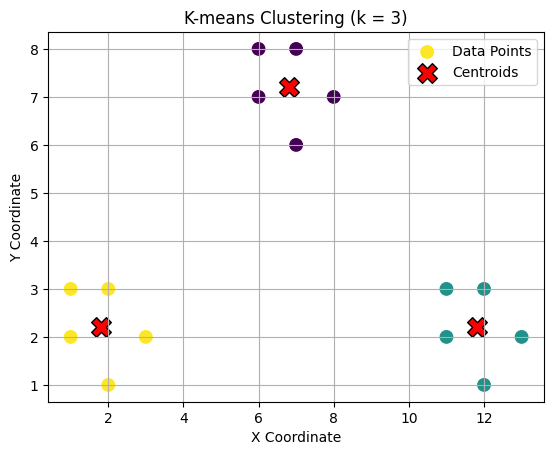

In [3]:

# Plot the data points by cluster
plt.scatter(X[:, 0], X[:, 1], c=labels,
            cmap="viridis", s=80,
            label="Data Points")

# Plot the cluster centroids
plt.scatter(centroids[:, 0], centroids[:, 1],
            c="red", marker="X", s=200,
            edgecolors="black", label="Centroids")

# Add labels and title
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("K-means Clustering (k = 3)")

# Add legend and grid
plt.legend()
plt.grid()

plt.show()


### Interpretation

The K-means algorithm successfully divided the 15 data points into three clusters, with five points assigned to each cluster.

The calculated centroids were (6.8, 7.2), (11.8, 2.2), and (1.8, 2.2). The graph shows that the data points are grouped around their respective centroids based on their distances.

The within-cluster sum of squares was 16.8, representing the total squared distance between the data points and their assigned centroids.

These results demonstrate how K-means can identify groups of similar observations without using predefined class labels.

## 3.6 Support Vector Machines

Support Vector Machines (SVM) are supervised machine learning methods used for classification and regression. In classification, SVM attempts to find a decision boundary that separates observations into different classes.

For linearly separable data, the decision boundary is represented by a hyperplane:

$$
w^T x+b=0
$$

where:

- **w** represents the weight vector.
- **x** represents the input features.
- **b** represents the bias term.

SVM attempts to maximize the margin between the decision boundary and the closest data points from each class. These closest points are called support vectors.

For a hard-margin linear SVM, the optimization problem is:

$$
\min_{w,b}\frac{1}{2}\|w\|^2
$$

subject to:

$$
y_i(w^Tx_i+b)\geq 1
$$

where yᵢ represents the class label, either -1 or 1.

In this example, we will use Python to classify two-dimensional data points using a linear SVM and visualize the decision boundary and support vectors.

In [4]:

# Create a two-dimensional dataset
X_svm = np.array([
    [1, 2], [2, 1], [2, 3],
    [3, 2], [1, 3], [3, 3],
    [6, 6], [7, 5], [7, 7],
    [8, 6], [6, 7], [8, 7]
])

# Assign class labels (-1 or 1)
y_svm = np.array([
    -1, -1, -1, -1, -1, -1,
     1,  1,  1,  1,  1,  1
])

# Train a linear Support Vector Machine
svm_model = SVC(kernel="linear", C=1000)
svm_model.fit(X_svm, y_svm)

# Predict the classes
svm_predictions = svm_model.predict(X_svm)

# Calculate classification accuracy
svm_accuracy = accuracy_score(y_svm, svm_predictions)

# Display results
print("SVM Predictions:")
print(svm_predictions)

print("\nClassification Accuracy:")
print(round(svm_accuracy, 4))

print("\nNumber of Support Vectors:")
print(len(svm_model.support_vectors_))

print("\nSupport Vectors:")
print(svm_model.support_vectors_)

print("\nWeight Vector:")
print(svm_model.coef_)

print("\nBias:")
print(svm_model.intercept_)


SVM Predictions:
[-1 -1 -1 -1 -1 -1  1  1  1  1  1  1]

Classification Accuracy:
1.0

Number of Support Vectors:
2

Support Vectors:
[[3. 3.]
 [6. 6.]]

Weight Vector:
[[0.33333333 0.33333333]]

Bias:
[-3.]


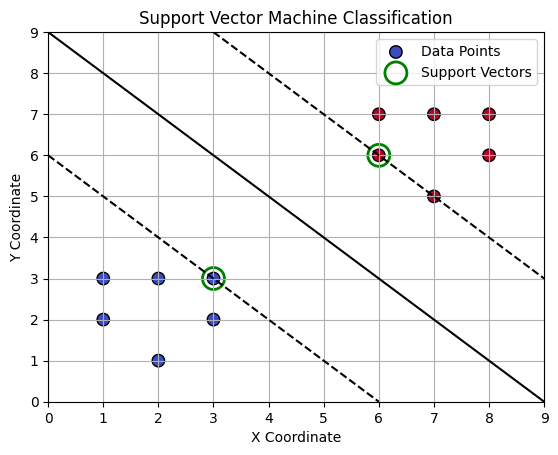

In [5]:

# Create a grid for the decision boundary
xx, yy = np.meshgrid(
    np.linspace(0, 9, 300),
    np.linspace(0, 9, 300)
)

# Calculate the SVM decision function
grid = np.c_[xx.ravel(), yy.ravel()]
Z = svm_model.decision_function(grid)
Z = Z.reshape(xx.shape)

# Plot the data points
plt.scatter(X_svm[:, 0], X_svm[:, 1],
            c=y_svm, cmap="coolwarm",
            s=80, edgecolors="black",
            label="Data Points")

# Plot decision boundary and margins
plt.contour(xx, yy, Z,
            levels=[-1, 0, 1],
            colors="black",
            linestyles=["--", "-", "--"])

# Highlight support vectors
plt.scatter(svm_model.support_vectors_[:, 0],
            svm_model.support_vectors_[:, 1],
            s=250, facecolors="none",
            edgecolors="green", linewidths=2,
            label="Support Vectors")

# Add labels and title
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("Support Vector Machine Classification")

plt.legend()
plt.grid()
plt.show()


### Interpretation

The Support Vector Machine successfully classified the 12 data points into two classes with an accuracy of 100% on the training dataset.

The model identified two support vectors at (3, 3) and (6, 6). These points determine the position of the decision boundary and the margins separating the classes.

The calculated weight vector was (0.3333, 0.3333), with a bias of -3. This produces the decision boundary x₁ + x₂ = 9.

The graph shows that the two classes are separated by the decision boundary, with the support vectors located along the margins.

These results demonstrate how SVM uses a maximum-margin decision boundary to classify linearly separable data.